# 🏠 Bài tập mở rộng: Tuning các mô hình hồi quy dự đoán giá nhà


## 🎯 Mục tiêu
- Dự đoán giá nhà là một bài toán hồi quy kinh điển trong lĩnh vực học máy, yêu cầu mô hình học được quan hệ phi tuyến giữa các đặc trưng (như thu nhập, mật độ dân cư, diện tích nhà, v.v.) và giá nhà.
- Các mô hình học máy có nhiều siêu tham số (hyperparameters) ảnh hưởng lớn đến hiệu suất dự đoán. Việc hiểu, tinh chỉnh và đánh giá các mô hình sẽ giúp:

  *   Hiểu được tác động của từng tham số lên kết quả dự đoán.
  *   Phân tích và trực quan hóa quá trình tuning qua biểu đồ parallel_coordinates.
  *  Kỹ thuật tuning hyperparameters bằng GridSearchCV,..


- Xây dựng và tinh chỉnh 5 mô hình hồi quy, so sánh hiệu năng, phân tích ảnh hưởng của từng tham số và rút ra kết luận về hiệu quả của từng mô hình. Tuning tham số bằng `GridSearchCV` cho 5 mô hình:
  - `SVR`
  - `KNeighborsRegressor`
  - `RandomForestRegressor`
  - `DecisionTreeRegressor`
  - `Ridge`
- Đánh giá hiệu suất mô hình bằng MSE, MAE và R².


In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge

# Tiền xử lý dữ liệu

In [60]:
# Đọc dữ liệu và xử lý
df = pd.read_csv('../data/USA_Housing.csv')
df = df.drop('Address', axis=1)

# Scale 2 cột đặc trưng
scale = MinMaxScaler()
df['Avg. Area Income'] = scale.fit_transform(np.array(df['Avg. Area Income']).reshape(-1, 1))
df['Area Population'] = scale.fit_transform(np.array(df['Area Population']).reshape(-1, 1))

# Tách X, y
y = df['Price']
x = df.drop('Price', axis=1)

# Chia train/test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.01, random_state=42)

In [61]:
def evaluate_model(model, param_grid, X_train, y_train, X_test, y_test, model_name="Model"):
    grid = GridSearchCV(model, param_grid, cv=5, scoring='mean_squared_error', n_jobs=-1)
    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\n📌 {model_name}")
    print("Best parameters:", grid.best_params_)
    print(f"Test MSE: {mse:.4f}")
    print(f"Test MAE: {mae:.4f}")
    print(f"Test R² : {r2:.4f}")

    return grid.best_estimator_


In [62]:
def compare_default_and_tuned_models(x_train, x_test, y_train, y_test, best_estimator, model_name="Model"):
    """
    So sánh trực quan mô hình mặc định và mô hình đã tuning cho bất kỳ mô hình hồi quy nào.
    """

    # Lấy class gốc của mô hình để tạo phiên bản mặc định
    model_class = best_estimator.__class__
    default_model = model_class()
    default_model.fit(x_train, y_train)
    y_pred_default = default_model.predict(x_test)
    y_pred_tuned = best_estimator.predict(x_test)

    # Tính metric cho cả hai mô hình
    metrics = lambda y_true, y_pred: {
        "MSE": mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred)
    }
    default_metrics = metrics(y_test, y_pred_default)
    tuned_metrics = metrics(y_test, y_pred_tuned)

    # Trực quan hóa
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Mô hình mặc định
    axes[0].scatter(y_test, y_pred_default, c='red', alpha=0.6)
    axes[0].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '-', label="Đường lý tưởng")
    axes[0].set_title(f"{model_name} - Mặc định\nMSE: {default_metrics['MSE']:.3f} | MAE: {default_metrics['MAE']:.3f}")
    axes[0].set_xlabel("Giá trị thực tế")
    axes[0].set_ylabel("Giá trị dự đoán")
    axes[0].legend()

    # Mô hình đã tuning
    axes[1].scatter(y_test, y_pred_tuned, c='blue', alpha=0.6)
    axes[1].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '-', label="Đường lý tưởng")
    axes[1].set_title(f"{model_name} - Tối ưu\nMSE: {tuned_metrics['MSE']:.3f} | MAE: {tuned_metrics['MAE']:.3f}")
    axes[1].set_xlabel("Giá trị thực tế")
    axes[1].set_ylabel("Giá trị dự đoán")
    axes[1].legend()

    plt.suptitle(f"So sánh hiệu suất: {model_name}", fontsize=14)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [63]:
# Xây dựng từ điển param_grids chứa các tập hợp siêu tham số cần thử nghiệm cho mỗi mô hình.

param_grids = {
    "SVR": {
        'C': [1, 10, 1000, 10000, 1000000],
        'epsilon': [0.01, 0.1, 1],
        'kernel': ['linear', 'rbf', 'poly']

    },
    "KNeighborsRegressor": {
        'n_neighbors': [3, 5, 7, 9, 11, 13],
        'weights': ['uniform', 'distance'],
        'p': [1, 2]
    },
    "RandomForestRegressor": {
        'n_estimators': [10, 50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    "DecisionTreeRegressor": {
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 4, 6],
        'min_samples_leaf': [1, 2]
    },
    "Ridge": {
        'alpha': [0.001, 0.01, 0.1, 1, 2],
        'solver': ['auto', 'svd', 'cholesky']
    }
}

In [64]:
# Tạo biểu đồ trực quan hóa kết quả tìm kiếm siêu tham số bằng biểu đồ parallel_coordinates
# Giúp hiểu ảnh hưởng của từng siêu tham số đến kết quả loss.

import plotly.express as px

def visualize_tuning_results(grid, model_name, loss_metric='mean_test_score', negate_score=True):
    results_df = pd.DataFrame(grid.cv_results_)

    # Lấy cột tham số và score
    param_cols = [col for col in results_df.columns if col.startswith('param_')]
    selected_cols = param_cols + [loss_metric]
    vis_df = results_df[selected_cols].copy()

    # Tạo cột Loss
    vis_df['Loss'] = -vis_df[loss_metric] if negate_score else vis_df[loss_metric]
    vis_df.drop(columns=[loss_metric], inplace=True)

    # Ánh xạ các giá trị chuỗi sang số để vẽ được
    str_mappings = {}  # lưu lại ánh xạ để hiển thị sau

    for col in param_cols:
        if vis_df[col].dtype == 'object':
            unique_vals = vis_df[col].unique()
            mapping = {val: idx for idx, val in enumerate(unique_vals)}
            str_mappings[col] = mapping
            vis_df[col] = vis_df[col].map(mapping)

    # Đổi tên cột cho ngắn gọn
    vis_df.rename(columns={col: col.replace('param_', '') for col in vis_df.columns}, inplace=True)

    # Vẽ biểu đồ
    fig = px.parallel_coordinates(
        vis_df,
        color='Loss',
        labels={col.replace('param_', ''): col.replace('param_', '') for col in param_cols} | {'Loss': 'Loss'},
        title=f"Tuning Visualization - {model_name}"
    )
    fig.show()

    if str_mappings:
        print(f"\n🔤 String-to-Int Mappings for {model_name}:")
        for col, mapping in str_mappings.items():
            print(f" - {col.replace('param_', '')}: {mapping}")



# Huấn luyện các mô hình

In [65]:
# Khởi tạo mô hình và dictionary lưu mô hình tốt nhất

models = {
    "SVR": SVR(),
    "KNeighborsRegressor": KNeighborsRegressor(),
    "RandomForestRegressor": RandomForestRegressor(random_state=42),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
    "Ridge": Ridge()
}

best_models = {}
model_results = {}

## Mô hình ***SVR***

🔍 Đang tuning mô hình: SVR...
📌 SVR
Best parameters: {'C': 1000000, 'epsilon': 0.01, 'kernel': 'linear'}
Test MSE: 9396052266.1842
Test MAE: 75002.0129
Test R² : 0.8973



🔤 String-to-Int Mappings for SVR:
 - kernel: {'linear': 0, 'rbf': 1, 'poly': 2}


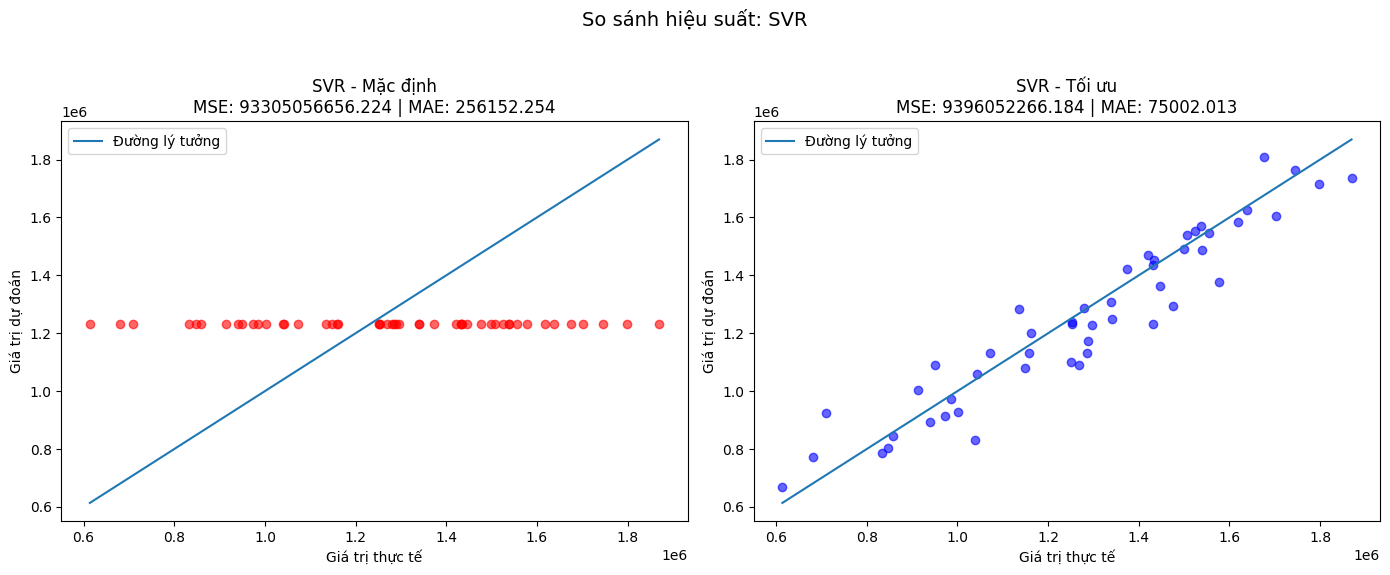

✅ Hoàn thành: SVR
--------------------------------------------------


In [66]:
# Chạy tuning và trực quan hóa cho mô hình SVR

name = "SVR"
model = models[name]
print(f"🔍 Đang tuning mô hình: {name}...")

grid = GridSearchCV(model, param_grids[name], cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(x_train, y_train)

y_pred = grid.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"📌 {name}")
print("Best parameters:", grid.best_params_)
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² : {r2:.4f}")

best_models[name] = grid.best_estimator_
model_results[name] = {
    "MSE": mse,
    "MAE": mae,
    "R2": r2
}

# Trực quan hóa kết quả tìm kiếm siêu tham số
visualize_tuning_results(grid, model_name=name)

# Trực quan hóa mức độ chính xác của mô hình khi dùng bộ tham số tối ưu và bộ tham số mặc định bằng cách so sánh giữa giá trị thực tế (y_test) và giá trị dự đoán (y_pred) thông qua biểu đồ phân tán.
compare_default_and_tuned_models(x_train, x_test, y_train, y_test, grid.best_estimator_, model_name=name)

print(f"✅ Hoàn thành: {name}\n{'-'*50}")



📊 Bảng MSE với kernel = 'linear':
param_epsilon          0.01          0.10          1.00
param_C                                                
1              1.242091e+11  1.242091e+11  1.242091e+11
10             1.177494e+11  1.177494e+11  1.177494e+11
1000           6.266185e+10  6.266185e+10  6.266183e+10
10000          1.322194e+10  1.322195e+10  1.322202e+10
1000000        1.027508e+10  1.027508e+10  1.027509e+10


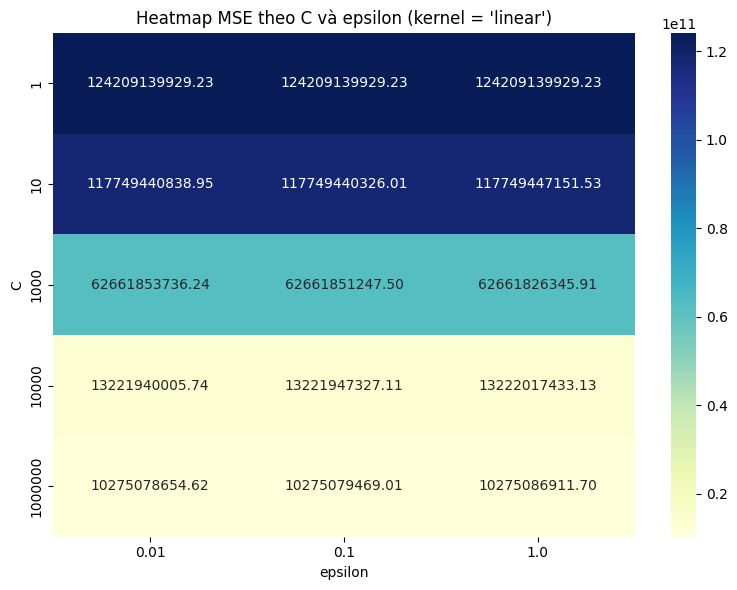


📊 Bảng MSE với kernel = 'rbf':
param_epsilon          0.01          0.10          1.00
param_C                                                
1              1.249921e+11  1.249921e+11  1.249921e+11
10             1.247032e+11  1.247032e+11  1.247032e+11
1000           1.041598e+11  1.041598e+11  1.041597e+11
10000          7.606344e+10  7.606344e+10  7.606344e+10
1000000        1.077833e+10  1.077833e+10  1.077833e+10


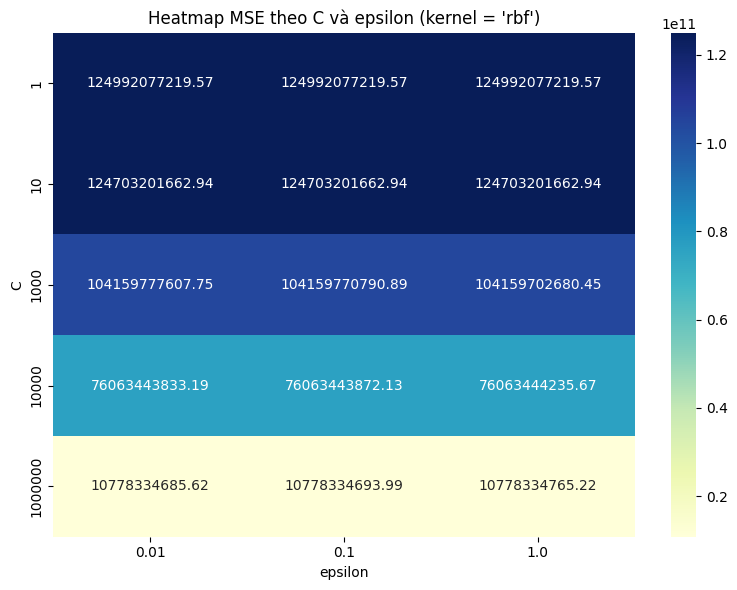


📊 Bảng MSE với kernel = 'poly':
param_epsilon          0.01          0.10          1.00
param_C                                                
1              1.238345e+11  1.238345e+11  1.238345e+11
10             1.151251e+11  1.151251e+11  1.151251e+11
1000           7.338844e+10  7.338844e+10  7.338843e+10
10000          2.406685e+10  2.406684e+10  2.406680e+10
1000000        1.348083e+10  1.348083e+10  1.348085e+10


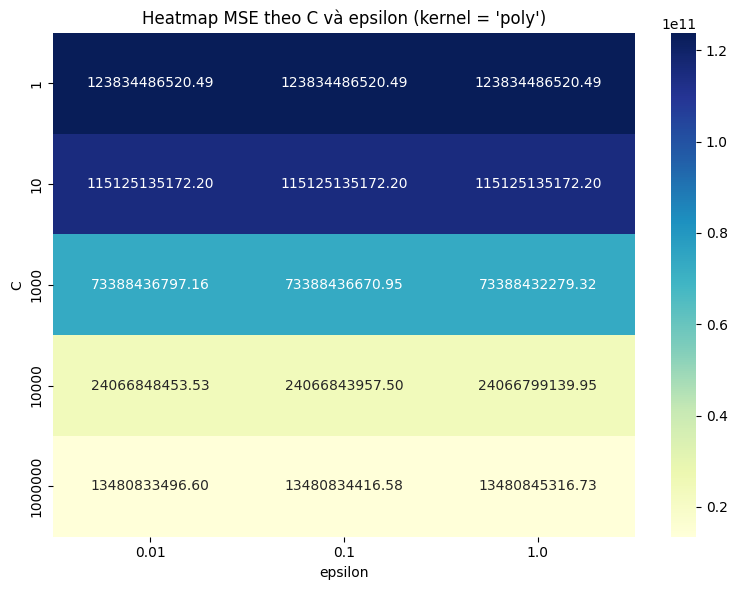

In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Lấy kết quả tuning từ GridSearchCV
results = pd.DataFrame(grid.cv_results_)
results['mean_squared_error'] = -results['mean_test_score']  # Chuyển về dương

# Duyệt từng loại kernel và tạo bảng pivot + heatmap
for kernel in results['param_kernel'].unique():
    subset = results[results['param_kernel'] == kernel]
    
    pivot = subset.pivot(index='param_C', columns='param_epsilon', values='mean_squared_error')
    
    print(f"\n📊 Bảng MSE với kernel = '{kernel}':")
    print(pivot.round(3))
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title(f"Heatmap MSE theo C và epsilon (kernel = '{kernel}')")
    plt.xlabel("epsilon")
    plt.ylabel("C")
    plt.tight_layout()
    plt.show()


In [68]:
import numpy as np
import matplotlib.pyplot as plt

def plot_svr_predictions(x_train, y_train, x_test, y_test, model, title="SVR Prediction"):
    # Dự đoán trên toàn bộ dữ liệu để vẽ đường hồi quy mượt
    x_all = np.linspace(x_train.min(), x_train.max(), 500).reshape(-1, 1)
    y_all_pred = model.predict(x_all)

    # Dự đoán trên tập test
    y_test_pred = model.predict(x_test)

    plt.figure(figsize=(10, 6))
    plt.scatter(x_train, y_train, color="gray", alpha=0.5, label="Train data")
    plt.scatter(x_test, y_test, color="blue", label="Test data")
    plt.plot(x_all, y_all_pred, color="red", label="SVR prediction (tuned)")
    plt.scatter(x_test, y_test_pred, color="green", label="Predicted (test)", marker="x")

    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 🧠 Câu hỏi phân tích
1. Dựa trên biểu đồ, bạn thấy tổ hợp giá trị nào cho ra Loss thấp nhất?

2. Có tham số nào dường như có ảnh hưởng lớn hơn đến xu hướng của hàm Loss so với các tham số khác không?

3. Nêu một đường trong biểu đồ cho thấy một cấu hình tệ (Loss cao), nếu có. Bạn có thể xác định được tham số nào gây ra điều đó?

4.  Khi lựa chọn bộ siêu tham số để huấn luyện mô hình, bộ siêu tham số sẽ xoay quanh các giá trị tham số là bao nhiêu? Vì sao

In [69]:
# Câu trả lời cho câu hỏi 1
'''
Tổ hợp này cho giá trị Loss thấp nhất là 10.28 B

{'C': 1000000, 'epsilon': 0.01, 'kernel': 'linear'}

'''

"\nTổ hợp này cho giá trị Loss thấp nhất là 10.28 B\n\n{'C': 1000000, 'epsilon': 0.01, 'kernel': 'linear'}\n\n"

In [70]:
# Câu trả lời cho câu hỏi 2
'''
Với cả 3 bộ kernel thì ta thấy epsilon không có ảnh hưởng nhiều 
C có ảnh hưởng rõ rệt MSE giảm mạnh khi giá trị C tăng từ 1 lên 1000000.

Nhìn tổng thể thì Kernel 'poly' có vẻ tối ưu nhất vì MSE giảm rõ rệt khi tăng giá trị C.

Nhưng với cái bộ tham số tốt nhất thì nó thuộc về linearlinear
'''

"\nVới cả 3 bộ kernel thì ta thấy epsilon không có ảnh hưởng nhiều \nC có ảnh hưởng rõ rệt MSE giảm mạnh khi giá trị C tăng từ 1 lên 1000000.\n\nNhìn tổng thể thì Kernel 'poly' có vẻ tối ưu nhất vì MSE giảm rõ rệt khi tăng giá trị C.\n\nNhưng với cái bộ tham số tốt nhất thì nó thuộc về linearlinear\n"

In [71]:
# Câu trả lời cho câu hỏi 3
'''
Một đường xấu cho loss cao là kernel linear, C = 1, epsilon = 0.01,  MSE = 1.242091e+11 (124B)

Nguyên nhân: Giá trị C quá nhỏ và không đủ mạnh để giảm bớt lỗi, khiến mô hình không thể "fit" với dữ liệu.
'''

'\nMột đường xấu cho loss cao là kernel linear, C = 1, epsilon = 0.01,  MSE = 1.242091e+11 (124B)\n\nNguyên nhân: Giá trị C quá nhỏ và không đủ mạnh để giảm bớt lỗi, khiến mô hình không thể "fit" với dữ liệu.\n'

In [72]:
# Câu trả lời cho câu hỏi 4

'''
xoay quanh bộ tham số này tại vì mình setup nó như vậy mà :v
"SVR": {
    'C': [1, 10, 1000, 10000, 1000000],
    'epsilon': [0.01, 0.1, 1],
    'kernel': ['linear', 'rbf', 'poly']
    
Bộ siêu tham số C thường sẽ xoay quanh các giá trị lớn, ví dụ như: 1, 10, 100, 1000, 10000, hoặc thậm chí lên tới 1000000.

Lý do: C là tham số điều chỉnh mức độ "hình phạt" cho các điểm ngoài các ranh giới phân cách trong không gian đặc trưng. Giá trị nhỏ của C có thể khiến mô hình dễ bị underfitting (quá đơn giản). Trong khi đó, giá trị lớn của C giúp mô hình fit dữ liệu tốt hơn nhưng có thể dẫn đến overfitting (quá khớp dữ liệu). Việc điều chỉnh C giữa các mức từ nhỏ đến lớn giúp cân bằng giữa bias và variance.

Các giá trị của epsilon thường dao động từ rất nhỏ như 0.01 đến các giá trị lớn như 1.0.

Lý do: epsilon xác định phạm vi trong đó các điểm dữ liệu được coi là "không có lỗi". Một giá trị epsilon quá nhỏ có thể dẫn đến overfitting, trong khi một giá trị quá lớn có thể làm mất đi sự tinh tế trong việc tìm kiếm mô hình tốt nhất. Việc lựa chọn epsilon hợp lý giúp kiểm soát sai số của mô hình.

kernel:

kernel thì nên chọn 3 cái này linear, rbf, và poly.


linear phù hợp với dữ liệu phân loại đơn giản hoặc tuyến tính.

rbf giúp xử lý các bài toán phi tuyến tính tốt hơn.

poly giúp tạo ra các đường biên phân chia phức tạp hơn với các mức độ khác nhau.

'''

'\nxoay quanh bộ tham số này tại vì mình setup nó như vậy mà :v\n"SVR": {\n    \'C\': [1, 10, 1000, 10000, 1000000],\n    \'epsilon\': [0.01, 0.1, 1],\n    \'kernel\': [\'linear\', \'rbf\', \'poly\']\n    \nBộ siêu tham số C thường sẽ xoay quanh các giá trị lớn, ví dụ như: 1, 10, 100, 1000, 10000, hoặc thậm chí lên tới 1000000.\n\nLý do: C là tham số điều chỉnh mức độ "hình phạt" cho các điểm ngoài các ranh giới phân cách trong không gian đặc trưng. Giá trị nhỏ của C có thể khiến mô hình dễ bị underfitting (quá đơn giản). Trong khi đó, giá trị lớn của C giúp mô hình fit dữ liệu tốt hơn nhưng có thể dẫn đến overfitting (quá khớp dữ liệu). Việc điều chỉnh C giữa các mức từ nhỏ đến lớn giúp cân bằng giữa bias và variance.\n\nCác giá trị của epsilon thường dao động từ rất nhỏ như 0.01 đến các giá trị lớn như 1.0.\n\nLý do: epsilon xác định phạm vi trong đó các điểm dữ liệu được coi là "không có lỗi". Một giá trị epsilon quá nhỏ có thể dẫn đến overfitting, trong khi một giá trị quá lớn có t

## Mô hình ***KNeighborsRegressor***

🔍 Đang tuning mô hình: KNeighborsRegressor...
📌 KNeighborsRegressor
Best parameters: {'n_neighbors': 5, 'p': 1, 'weights': 'distance'}
Test MSE: 34020326240.1504
Test MAE: 145917.3538
Test R² : 0.6282



🔤 String-to-Int Mappings for KNeighborsRegressor:
 - weights: {'uniform': 0, 'distance': 1}


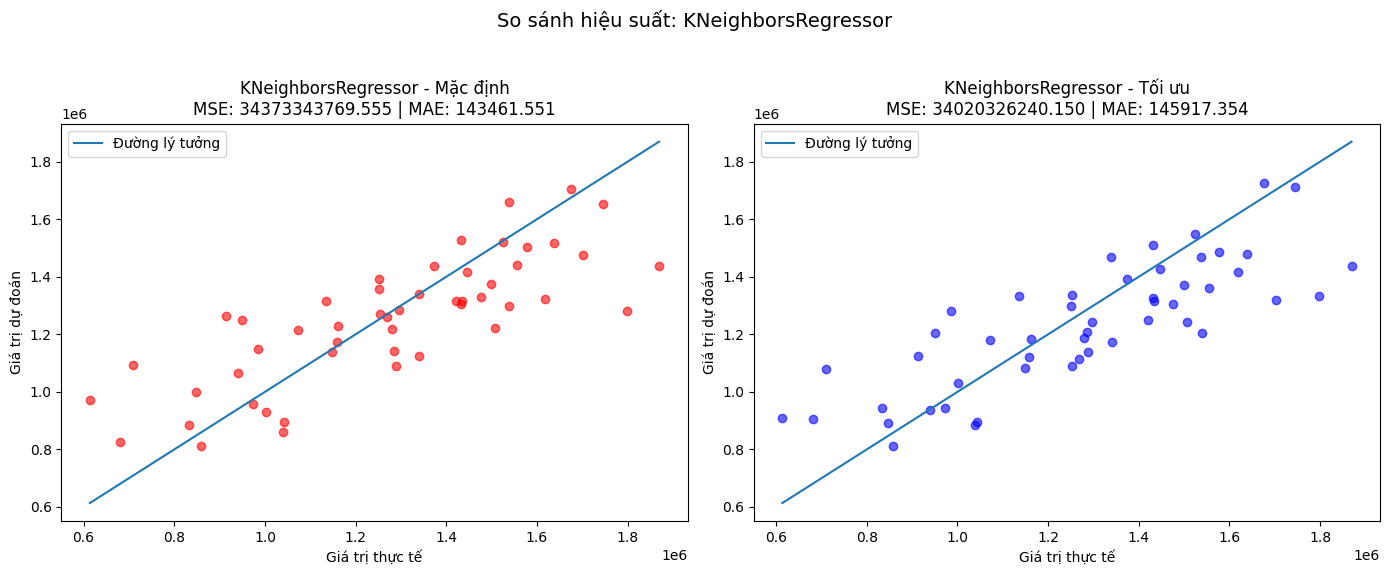

✅ Hoàn thành: KNeighborsRegressor
--------------------------------------------------


In [73]:
# Chạy tuning và trực quan hóa cho mô hình KNeighborsRegressor

name = "KNeighborsRegressor"
model = models[name]
print(f"🔍 Đang tuning mô hình: {name}...")

grid = GridSearchCV(model, param_grids[name], cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(x_train, y_train)

y_pred = grid.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"📌 {name}")
print("Best parameters:", grid.best_params_)
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² : {r2:.4f}")

best_models[name] = grid.best_estimator_
model_results[name] = {
    "MSE": mse,
    "MAE": mae,
    "R2": r2
}

# Trực quan hóa kết quả tìm kiếm siêu tham số
visualize_tuning_results(grid, model_name=name)

# Trực quan hóa mức độ chính xác của mô hình khi dùng bộ tham số tối ưu và bộ tham số mặc định bằng cách so sánh giữa giá trị thực tế (y_test) và giá trị dự đoán (y_pred) thông qua biểu đồ phân tán.
compare_default_and_tuned_models(x_train, x_test, y_train, y_test, grid.best_estimator_, model_name=name)

print(f"✅ Hoàn thành: {name}\n{'-'*50}")


In [74]:
# results = pd.DataFrame(grid.cv_results_)
# results

In [75]:
import pandas as pd

def create_mse_table_knn(grid):
    # Lấy toàn bộ kết quả từ quá trình GridSearch
    results = pd.DataFrame(grid.cv_results_)

    # Đổi sign vì scoring='neg_mean_squared_error'
    results['mean_MSE'] = -results['mean_test_score']

    # Tạo bảng pivot để xem MSE theo từng tổ hợp tham số
    for w in results['param_weights'].unique():
        sub = results[results['param_weights'] == w]
        table = sub.pivot_table(
            index='param_n_neighbors',
            columns='param_p',
            values='mean_MSE'
        )
        print(f"\n📊 Bảng MSE với weights = '{w}':")
        print(table.round(2))  # Làm tròn cho dễ nhìn
create_mse_table_knn(grid)



📊 Bảng MSE với weights = 'uniform':
param_p                       1             2
param_n_neighbors                            
3                  4.718158e+10  4.757954e+10
5                  4.426988e+10  4.631290e+10
7                  4.480904e+10  4.722950e+10
9                  4.556087e+10  4.848456e+10
11                 4.619575e+10  4.995738e+10
13                 4.703552e+10  5.148215e+10

📊 Bảng MSE với weights = 'distance':
param_p                       1             2
param_n_neighbors                            
3                  4.644553e+10  4.668669e+10
5                  4.312878e+10  4.482448e+10
7                  4.325627e+10  4.538897e+10
9                  4.378750e+10  4.630961e+10
11                 4.427662e+10  4.748835e+10
13                 4.497821e+10  4.876766e+10


### 🧠 Câu hỏi phân tích
1. Dựa trên biểu đồ, bạn thấy tổ hợp giá trị nào cho ra Loss thấp nhất?

2. Có tham số nào dường như có ảnh hưởng lớn hơn đến xu hướng của hàm Loss so với các tham số khác không?

3. Nêu một đường trong biểu đồ cho thấy một cấu hình tệ (Loss cao), nếu có. Bạn có thể xác định được tham số nào gây ra điều đó?

4.  Khi lựa chọn bộ siêu tham số để huấn luyện mô hình, bộ tham số sẽ xoay quanh các giá trị siêu tham số là bao nhiêu? Vì sao?

In [76]:
# Câu trả lời cho câu hỏi 1
'''
Với weights = 'distance', n_neighbors = 5, p = 1 có MSE thấp nhất: MSE = 4.31e+10

Đây chính là tổ hợp siêu tham số tốt nhất trong toàn bộ kết quả.
'''

"\nVới weights = 'distance', n_neighbors = 5, p = 1 có MSE thấp nhất: MSE = 4.31e+10\n\nĐây chính là tổ hợp siêu tham số tốt nhất trong toàn bộ kết quả.\n"

In [77]:
# Câu trả lời cho câu hỏi 2

'''
n_neighbors: Khi tăng n_neighbors, MSE có xu hướng tăng nhẹ mô hình ít linh hoạt hơn, mất chi tiết


Với p = 1 (Manhattan), MSE luôn thấp hơn so với p = 2 (Euclidean)


Khi so sánh uniform vs distance ở cùng n_neighbors và p, thì distance thường cho MSE thấp hơn  phản ánh ảnh hưởng rõ rệt

weights có ảnh hưởng rõ rệt nhất
'''

'\nn_neighbors: Khi tăng n_neighbors, MSE có xu hướng tăng nhẹ mô hình ít linh hoạt hơn, mất chi tiết\n\n\nVới p = 1 (Manhattan), MSE luôn thấp hơn so với p = 2 (Euclidean)\n\n\nKhi so sánh uniform vs distance ở cùng n_neighbors và p, thì distance thường cho MSE thấp hơn  phản ánh ảnh hưởng rõ rệt\n\nweights có ảnh hưởng rõ rệt nhất\n'

In [78]:
# Câu trả lời cho câu hỏi 3
'''
Nhìn bảng weights = 'uniform', n_neighbors = 13, p = 2:

MSE cao nhất: 5.15e+10

nguyên nhân chắc là dodo

n_neighbors = 13: quá lớn mô hình quá đơn giản, mất chi tiết.

p = 2: dùng khoảng cách Euclidean không tối ưu trong trường hợp này.

weights = 'uniform': không ưu tiên các láng giềng gần hơn.
'''

"\nNhìn bảng weights = 'uniform', n_neighbors = 13, p = 2:\n\nMSE cao nhất: 5.15e+10\n\nnguyên nhân chắc là dodo\n\nn_neighbors = 13: quá lớn mô hình quá đơn giản, mất chi tiết.\n\np = 2: dùng khoảng cách Euclidean không tối ưu trong trường hợp này.\n\nweights = 'uniform': không ưu tiên các láng giềng gần hơn.\n"

In [79]:
# Câu trả lời cho câu hỏi 4
'''
weights: nên chọn 'distance' giúp mô hình ưu tiên các láng giềng gần, rõ ràng cải thiện MSE

p: nên chọn 1 (Manhattan) consistently thấp hơn p = 2

n_neighbors: khoảng 5-7 đạt MSE thấp và ổn định.
'''

"\nweights: nên chọn 'distance' giúp mô hình ưu tiên các láng giềng gần, rõ ràng cải thiện MSE\n\np: nên chọn 1 (Manhattan) consistently thấp hơn p = 2\n\nn_neighbors: khoảng 5-7 đạt MSE thấp và ổn định.\n"

## Mô hình ***RandomForestRegressor***

In [80]:
name = "RandomForestRegressor"
model = models[name]

🔍 Đang tuning mô hình: RandomForestRegressor...
📌 RandomForestRegressor
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Test MSE: 12812238665.5309
Test MAE: 79055.6054
Test R² : 0.8600



🔤 String-to-Int Mappings for RandomForestRegressor:
 - max_depth: {None: 0, 10: 1, 20: 2}


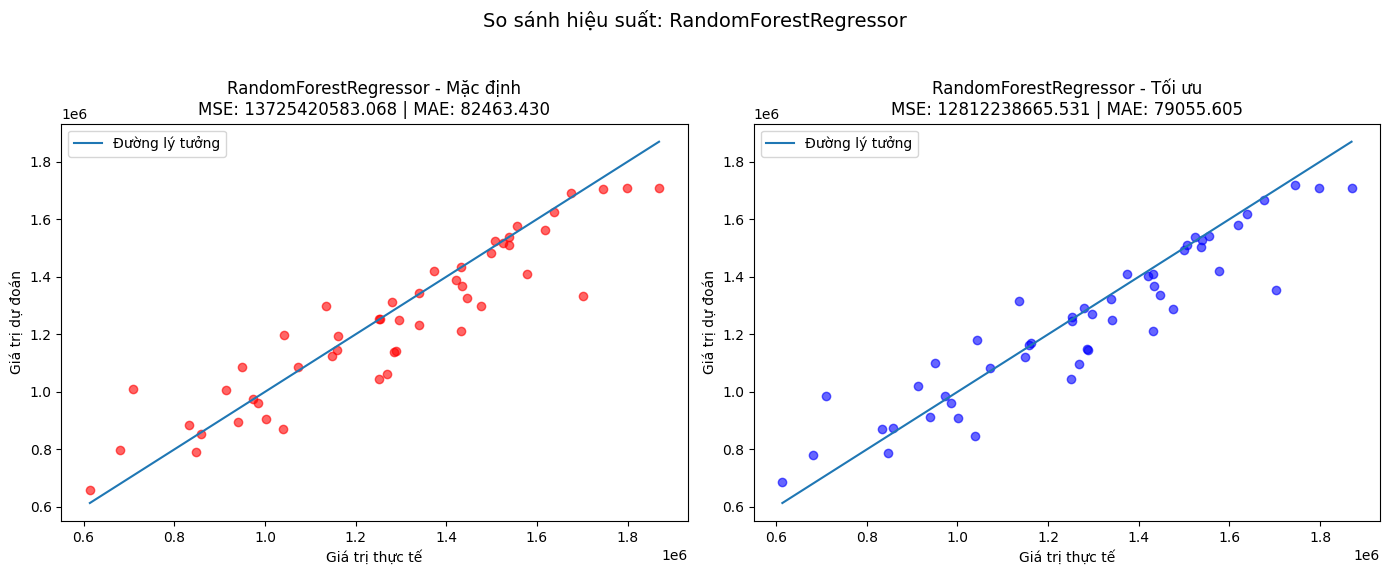

✅ Hoàn thành: RandomForestRegressor
--------------------------------------------------


In [81]:
# Chạy tuning và trực quan hóa cho mô hình RandomForestRegressor

name = "RandomForestRegressor"
model = models[name]
print(f"🔍 Đang tuning mô hình: {name}...")

grid = GridSearchCV(model, param_grids[name], cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(x_train, y_train)

y_pred = grid.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"📌 {name}")
print("Best parameters:", grid.best_params_)
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² : {r2:.4f}")

best_models[name] = grid.best_estimator_
model_results[name] = {
    "MSE": mse,
    "MAE": mae,
    "R2": r2
}

# Trực quan hóa kết quả tìm kiếm siêu tham số
visualize_tuning_results(grid, model_name=name)

# Trực quan hóa mức độ chính xác của mô hình khi dùng bộ tham số tối ưu và bộ tham số mặc định bằng cách so sánh giữa giá trị thực tế (y_test) và giá trị dự đoán (y_pred) thông qua biểu đồ phân tán.
compare_default_and_tuned_models(x_train, x_test, y_train, y_test, grid.best_estimator_, model_name=name)

print(f"✅ Hoàn thành: {name}\n{'-'*50}")

In [82]:
# Lấy kết quả từ GridSearchCV
results = pd.DataFrame(grid.cv_results_)

# Tạo bảng MSE cho từng max_depth riêng biệt
for depth in param_grids["RandomForestRegressor"]['max_depth']:
    subset = results[results['param_max_depth'] == depth]
    
    pivot = subset.pivot_table(
        index='param_n_estimators',
        columns='param_min_samples_split',
        values='mean_test_score'
    )

    # Vì GridSearchCV dùng negative MSE, ta chuyển về dương
    pivot = -pivot

    print(f"\n📊 Bảng MSE với max_depth = {depth}:")
    display(pivot)


📊 Bảng MSE với max_depth = None:


param_min_samples_split
param_n_estimators



📊 Bảng MSE với max_depth = 10:


param_min_samples_split,2,5
param_n_estimators,,
10,1.609548e+10,1.606627e+10
50,1.479084e+10,1.477600e+10
100,1.464057e+10,1.463166e+10
200,1.452981e+10,1.452283e+10



📊 Bảng MSE với max_depth = 20:


param_min_samples_split,2,5
param_n_estimators,,
10,1.610086e+10,1.594533e+10
50,1.464587e+10,1.458139e+10
100,1.445355e+10,1.443689e+10
200,1.431212e+10,1.430094e+10


### 🧠 Câu hỏi phân tích
1. Dựa trên biểu đồ, bạn thấy tổ hợp giá trị nào cho ra Loss thấp nhất?

2. Có tham số nào dường như có ảnh hưởng lớn hơn đến xu hướng của hàm Loss so với các tham số khác không?

3. Nêu một đường trong biểu đồ cho thấy một cấu hình tệ (Loss cao), nếu có. Bạn có thể xác định được tham số nào gây ra điều đó?

4.  Khi lựa chọn bộ siêu tham số để huấn luyện mô hình, bộ tham số sẽ xoay quanh các giá trị siêu tham số là bao nhiêu? Vì sao

In [83]:
# Câu trả lời cho câu hỏi 1

"""

loss thấp nhất là 1.430094e+10
với bộ tham số max_depth = 20, n_estimators = 200, min_samples_split = 5

"""


'\n\nloss thấp nhất là 1.430094e+10\nvới bộ tham số max_depth = 20, n_estimators = 200, min_samples_split = 5\n\n'

In [84]:
# Câu trả lời cho câu hỏi 2

"""
n_estimators ảnh hưởng lớn nhất, sau đó là max_depth

"""

'\nn_estimators ảnh hưởng lớn nhất, sau đó là max_depth\n\n'

In [85]:
# Câu trả lời cho câu hỏi 3
"""
cấu hình tệ nhất: max_depth = 10, n_estimators = 10, min_samples_split = 2
MSE = 1.609548e+10

Nguyên nhân:
Số lượng cây (n_estimators) quá ít mô hình không đủ mạnh.

max_depth = 10 cũng chưa đủ sâu để biểu diễn phức tạp cả 2 tham số này góp phần làm mô hình yếu.
"""

'\ncấu hình tệ nhất: max_depth = 10, n_estimators = 10, min_samples_split = 2\nMSE = 1.609548e+10\n\nNguyên nhân:\nSố lượng cây (n_estimators) quá ít mô hình không đủ mạnh.\n\nmax_depth = 10 cũng chưa đủ sâu để biểu diễn phức tạp cả 2 tham số này góp phần làm mô hình yếu.\n'

In [86]:
# Câu trả lời cho câu hỏi 4
"""
n_estimators: từ 100 -> 300 (có thể thử thêm 300 hoặc 500 nếu thời gian cho phép).

max_depth: 20 trở lên, hoặc thử None (cây phát triển tự nhiên) để kiểm chứng.

min_samples_split: giữ ở 2 và 5, không cần mở rộng nhiều trừ khi muốn chống overfitting.


Vì MSE tiếp tục giảm khi n_estimators và max_depth tăng.

Nhưng giảm chậm dần -> nên thử vài giá trị cao hơn để tìm ngưỡng ổn định (diminishing returns).
"""

'\nn_estimators: từ 100 -> 300 (có thể thử thêm 300 hoặc 500 nếu thời gian cho phép).\n\nmax_depth: 20 trở lên, hoặc thử None (cây phát triển tự nhiên) để kiểm chứng.\n\nmin_samples_split: giữ ở 2 và 5, không cần mở rộng nhiều trừ khi muốn chống overfitting.\n\n\nVì MSE tiếp tục giảm khi n_estimators và max_depth tăng.\n\nNhưng giảm chậm dần -> nên thử vài giá trị cao hơn để tìm ngưỡng ổn định (diminishing returns).\n'

## Mô hình ***DecisionTreeRegressor***

🔍 Đang tuning mô hình: DecisionTreeRegressor...
📌 DecisionTreeRegressor
Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 6}
Test MSE: 26104444188.5141
Test MAE: 130362.3806
Test R² : 0.7147



🔤 String-to-Int Mappings for DecisionTreeRegressor:
 - max_depth: {None: 0, 5: 1, 10: 2}


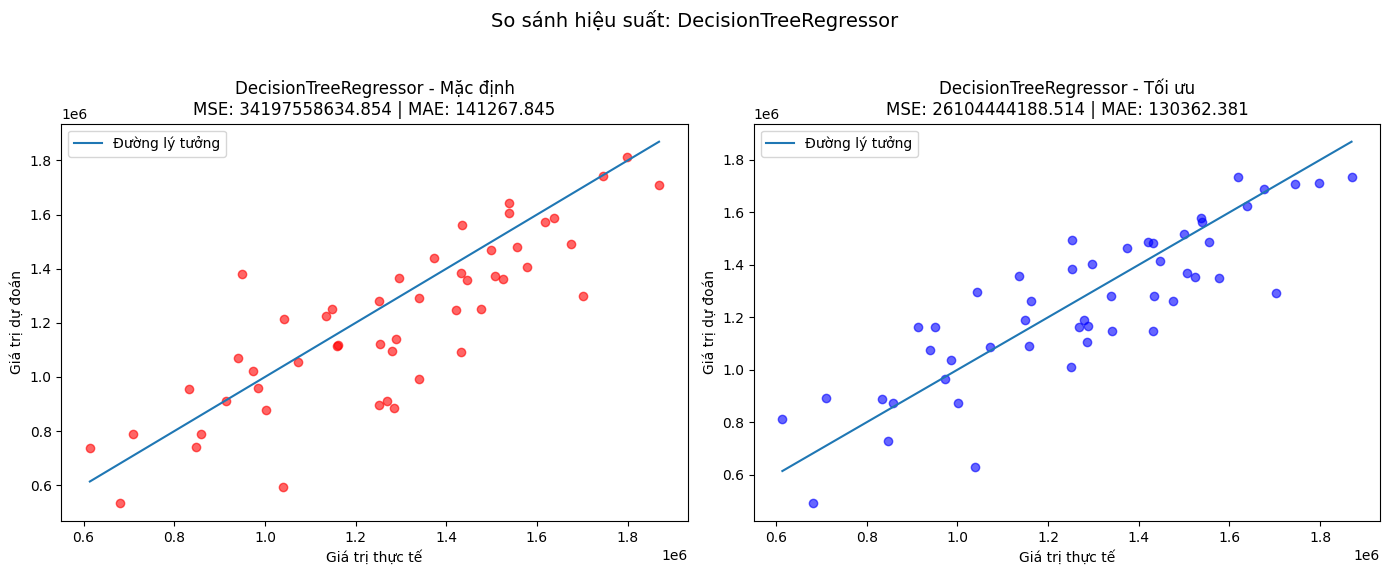

✅ Hoàn thành: DecisionTreeRegressor
--------------------------------------------------


In [87]:
# Chạy tuning và trực quan hóa cho mô hình DecisionTreeRegressor

name = "DecisionTreeRegressor"
model = models[name]
print(f"🔍 Đang tuning mô hình: {name}...")

grid = GridSearchCV(model, param_grids[name], cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(x_train, y_train)

y_pred = grid.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"📌 {name}")
print("Best parameters:", grid.best_params_)
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² : {r2:.4f}")

best_models[name] = grid.best_estimator_
model_results[name] = {
    "MSE": mse,
    "MAE": mae,
    "R2": r2
}

# Trực quan hóa kết quả tìm kiếm siêu tham số
visualize_tuning_results(grid, model_name=name)

# Trực quan hóa mức độ chính xác của mô hình khi dùng bộ tham số tối ưu và bộ tham số mặc định bằng cách so sánh giữa giá trị thực tế (y_test) và giá trị dự đoán (y_pred) thông qua biểu đồ phân tán.
compare_default_and_tuned_models(x_train, x_test, y_train, y_test, grid.best_estimator_, model_name=name)

print(f"✅ Hoàn thành: {name}\n{'-'*50}")

In [88]:
from itertools import product

# Lấy kết quả từ GridSearchCV
results = pd.DataFrame(grid.cv_results_)

# Tách theo từng max_depth để dễ trực quan
for max_depth_val in param_grids["DecisionTreeRegressor"]["max_depth"]:
    subset = results[results['param_max_depth'] == max_depth_val]

    pivot = subset.pivot_table(
        index="param_min_samples_split",
        columns="param_min_samples_leaf",
        values="mean_test_score"
    )

    pivot = -pivot  # Chuyển negative MSE thành positive
    print(f"\n📊 Bảng MSE với max_depth = {max_depth_val}:")
    display(pivot)



📊 Bảng MSE với max_depth = None:


param_min_samples_leaf
param_min_samples_split



📊 Bảng MSE với max_depth = 5:


param_min_samples_leaf,1,2
param_min_samples_split,,
2,4.179670e+10,4.181750e+10
4,4.179670e+10,4.181750e+10
6,4.179670e+10,4.181750e+10



📊 Bảng MSE với max_depth = 10:


param_min_samples_leaf,1,2
param_min_samples_split,,
2,2.837178e+10,2.752786e+10
4,2.799998e+10,2.752786e+10
6,2.755223e+10,2.711513e+10


### 🧠 Câu hỏi phân tích
1. Dựa trên biểu đồ, bạn thấy tổ hợp giá trị nào cho ra Loss thấp nhất?

2. Có tham số nào dường như có ảnh hưởng lớn hơn đến xu hướng của hàm Loss so với các tham số khác không?

3. Nêu một đường trong biểu đồ cho thấy một cấu hình tệ (Loss cao), nếu có. Bạn có thể xác định được tham số nào gây ra điều đó?

4.  Khi lựa chọn bộ siêu tham số để huấn luyện mô hình, bộ tham số sẽ xoay quanh các giá trị siêu tham số là bao nhiêu? Vì sao

In [89]:
# Câu trả lời cho câu hỏi 1

'''
Cấu hình tốt nhất (MSE thấp nhất): max_depth = 10, min_samples_split = 6, min_samples_leaf = 2

MSE = 2.711513e+10

Đây là cấu hình tốt nhất vì nó cho ra MSE nhỏ nhất trong tất cả các bảng.
'''

'\nCấu hình tốt nhất (MSE thấp nhất): max_depth = 10, min_samples_split = 6, min_samples_leaf = 2\n\nMSE = 2.711513e+10\n\nĐây là cấu hình tốt nhất vì nó cho ra MSE nhỏ nhất trong tất cả các bảng.\n'

In [90]:
# Câu trả lời cho câu hỏi 2
'''
max_depth là tham số ảnh hưởng lớn nhất đến loss trong trường hợp này 
'''

'\nmax_depth là tham số ảnh hưởng lớn nhất đến loss trong trường hợp này \n'

In [91]:
# Câu trả lời cho câu hỏi 3
'''
Cấu hình tệ nhất: max_depth = 5, bất kỳ giá trị nào cho min_samples_split và min_samples_leaf

MSE luôn quanh ~4.18e+10

Tham số gây ra điều này: Rõ ràng là do max_depth = 5 → mô hình quá đơn giản, dẫn đến underfitting.
'''

'\nCấu hình tệ nhất: max_depth = 5, bất kỳ giá trị nào cho min_samples_split và min_samples_leaf\n\nMSE luôn quanh ~4.18e+10\n\nTham số gây ra điều này: Rõ ràng là do max_depth = 5 → mô hình quá đơn giản, dẫn đến underfitting.\n'

In [92]:
# Câu trả lời cho câu hỏi 4
'''
max_depth: Nên thử từ 10 trở lên hoặc để None nếu không bị overfitting.

min_samples_leaf: Tốt nhất đang là 2, nên thử thêm 3, 4.

min_samples_split: 6 cho kết quả tốt, nhưng chênh lệch không quá lớn, thử quanh 4 –>8.

Vì trong quá trình tuning vừa rồi, các giá trị như max_depth=10, min_samples_leaf=2, 
min_samples_split=6 đã cho kết quả tốt nhất -> ta mở rộng thử nghiệm quanh các giá trị đó để tối ưu thêm.

'''

'\nmax_depth: Nên thử từ 10 trở lên hoặc để None nếu không bị overfitting.\n\nmin_samples_leaf: Tốt nhất đang là 2, nên thử thêm 3, 4.\n\nmin_samples_split: 6 cho kết quả tốt, nhưng chênh lệch không quá lớn, thử quanh 4 –>8.\n\nVì trong quá trình tuning vừa rồi, các giá trị như max_depth=10, min_samples_leaf=2, \nmin_samples_split=6 đã cho kết quả tốt nhất -> ta mở rộng thử nghiệm quanh các giá trị đó để tối ưu thêm.\n\n'

## Mô hình ***Ridge***

🔍 Đang tuning mô hình: Ridge...
📌 Ridge
Best parameters: {'alpha': 0.001, 'solver': 'auto'}
Test MSE: 9405945341.4754
Test MAE: 75146.1247
Test R² : 0.8972



🔤 String-to-Int Mappings for Ridge:
 - solver: {'auto': 0, 'svd': 1, 'cholesky': 2}


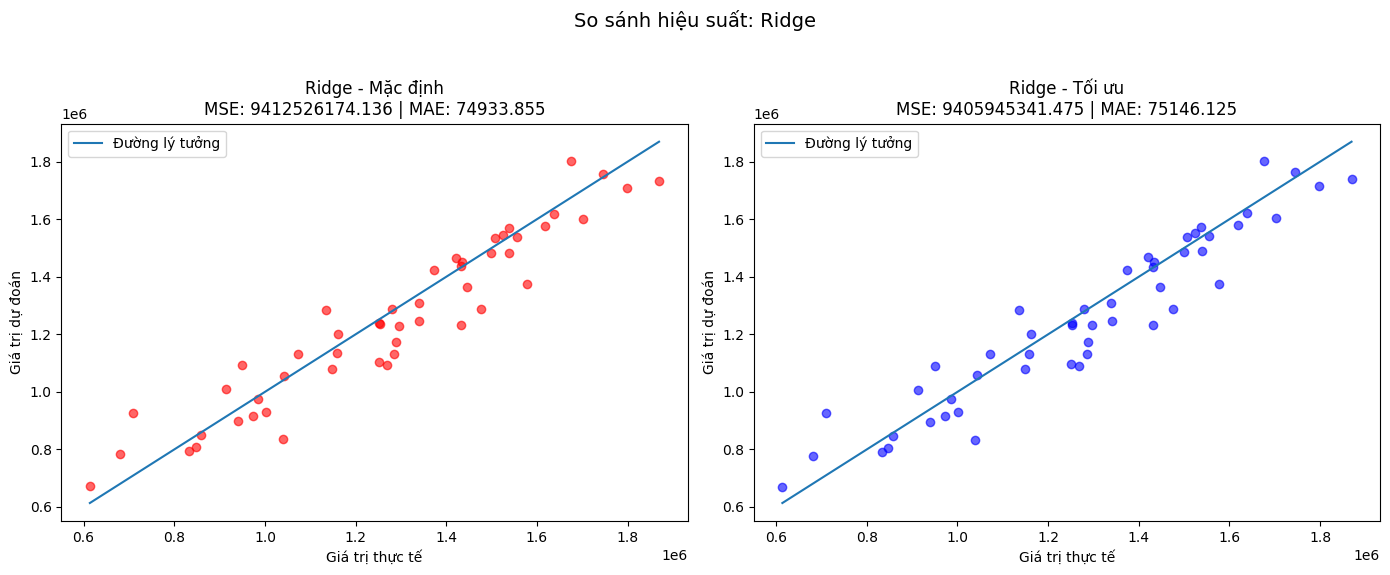

✅ Hoàn thành: Ridge
--------------------------------------------------


In [93]:
# Chạy tuning và trực quan hóa cho mô hình Ridge

name = "Ridge"
model = models[name]
print(f"🔍 Đang tuning mô hình: {name}...")

grid = GridSearchCV(model, param_grids[name], cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(x_train, y_train)

y_pred = grid.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"📌 {name}")
print("Best parameters:", grid.best_params_)
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² : {r2:.4f}")
model_results[name] = {
    "MSE": mse,
    "MAE": mae,
    "R2": r2
}

best_models[name] = grid.best_estimator_
model_results[name] = {
    "MSE": mse,
    "MAE": mae,
    "R2": r2
}

# Trực quan hóa kết quả tìm kiếm siêu tham số
visualize_tuning_results(grid, model_name=name)

# Trực quan hóa mức độ chính xác của mô hình khi dùng bộ tham số tối ưu và bộ tham số mặc định bằng cách so sánh giữa giá trị thực tế (y_test) và giá trị dự đoán (y_pred) thông qua biểu đồ phân tán.
compare_default_and_tuned_models(x_train, x_test, y_train, y_test, grid.best_estimator_, model_name=name)


print(f"✅ Hoàn thành: {name}\n{'-'*50}")

In [94]:
# Hàm tạo bảng MSE từ kết quả GridSearchCV
def create_mse_table(grid_result, param_name_1, param_name_2):
    # Lấy giá trị MSE từ kết quả của GridSearchCV
    mse_values = grid_result.cv_results_['mean_test_score']
    
    # Định dạng lại bảng thành 2D
    mse_table = pd.DataFrame(
        mse_values.reshape(len(grid_result.param_grid[param_name_1]), len(grid_result.param_grid[param_name_2])),
        columns=[f'{param_name_2}={x}' for x in grid_result.param_grid[param_name_2]],
        index=[f'{param_name_1}={x}' for x in grid_result.param_grid[param_name_1]]
    )
    
    # In ra bảng MSE
    return mse_table

# Giả sử bạn đã chạy GridSearchCV cho mô hình Ridge
# Thông số cho Ridge:
param_grids_ridge = {
    'alpha': [0.001, 0.01, 0.1, 1, 2],
    'solver': ['auto', 'svd', 'cholesky']
}

# Tạo bảng MSE cho mô hình Ridge với các tham số alpha và solver
mse_table_ridge = create_mse_table(grid, 'alpha', 'solver')

# Hiển thị bảng MSE
print(mse_table_ridge)

# Lưu bảng MSE vào file CSV nếu cần
mse_table_ridge.to_csv('mse_table_ridge.csv', index=True)

              solver=auto    solver=svd  solver=cholesky
alpha=0.001 -1.026026e+10 -1.026026e+10    -1.026026e+10
alpha=0.01  -1.026027e+10 -1.026027e+10    -1.026027e+10
alpha=0.1   -1.026052e+10 -1.026052e+10    -1.026052e+10
alpha=1     -1.028096e+10 -1.028096e+10    -1.028096e+10
alpha=2     -1.033934e+10 -1.033934e+10    -1.033934e+10


### 🧠 Câu hỏi phân tích
1. Dựa trên biểu đồ, bạn thấy tổ hợp giá trị nào cho ra Loss thấp nhất?

2. Có tham số nào dường như có ảnh hưởng lớn hơn đến xu hướng của hàm Loss so với các tham số khác không?

3. Nêu một đường trong biểu đồ cho thấy một cấu hình tệ (Loss cao), nếu có. Bạn có thể xác định được tham số nào gây ra điều đó?

4.  Khi lựa chọn bộ siêu tham số để huấn luyện mô hình, bộ siêu tham số sẽ xoay quanh các giá trị tham số là bao nhiêu? Vì sao

In [95]:
# Câu trả lời cho câu hỏi 1

"""
Tổ hợp giá trị có MSE thấp nhất là khi alpha=0.001 và bất kỳ solver nào (auto, svd, cholesky). MSE tại tổ hợp này là -1.026026e+10, là giá trị nhỏ nhất trong bảng.
"""

'\nTổ hợp giá trị có MSE thấp nhất là khi alpha=0.001 và bất kỳ solver nào (auto, svd, cholesky). MSE tại tổ hợp này là -1.026026e+10, là giá trị nhỏ nhất trong bảng.\n'

In [96]:
# Câu trả lời cho câu hỏi 2
"""
Tham số ảnh hưởng lớn hơn là alpha. Nhìn vào bảng, khi alpha tăng (từ 0.001 lên 2), MSE cũng tăng dần, cho thấy sự thay đổi trong alpha có ảnh hưởng đáng kể đến Loss của mô hình.
"""

'\nTham số ảnh hưởng lớn hơn là alpha. Nhìn vào bảng, khi alpha tăng (từ 0.001 lên 2), MSE cũng tăng dần, cho thấy sự thay đổi trong alpha có ảnh hưởng đáng kể đến Loss của mô hình.\n'

In [97]:
# Câu trả lời cho câu hỏi 3
"""
Cấu hình có MSE cao nhất là khi alpha=2 với bất kỳ solver nào. MSE tại đây là -1.033934e+10, cao nhất trong bảng.

Tham số alpha lớn hơn 1 có xu hướng gây ra MSE cao hơn, điều này có thể do overfitting khi mô hình phức tạp hơn với giá trị alpha lớn.
"""

'\nCấu hình có MSE cao nhất là khi alpha=2 với bất kỳ solver nào. MSE tại đây là -1.033934e+10, cao nhất trong bảng.\n\nTham số alpha lớn hơn 1 có xu hướng gây ra MSE cao hơn, điều này có thể do overfitting khi mô hình phức tạp hơn với giá trị alpha lớn.\n'

In [98]:
# Câu trả lời cho câu hỏi 4
"""
Bộ siêu tham số tối ưu sẽ xoay quanh giá trị alpha=0.001, vì đây là giá trị mang lại MSE thấp nhất trong tất cả các tham số alpha.

Về solver, không có sự khác biệt đáng kể giữa các giá trị của solver, do đó có thể sử dụng bất kỳ solver nào mà không làm ảnh hưởng nhiều đến hiệu suất của mô hình.

Tóm lại, khi lựa chọn bộ siêu tham số, bạn nên ưu tiên chọn alpha=0.001 vì đây là giá trị cho kết quả tốt nhất, trong khi solver có thể được lựa chọn một cách linh hoạt 
mà không lo ảnh hưởng đến kết quả.
"""

'\nBộ siêu tham số tối ưu sẽ xoay quanh giá trị alpha=0.001, vì đây là giá trị mang lại MSE thấp nhất trong tất cả các tham số alpha.\n\nVề solver, không có sự khác biệt đáng kể giữa các giá trị của solver, do đó có thể sử dụng bất kỳ solver nào mà không làm ảnh hưởng nhiều đến hiệu suất của mô hình.\n\nTóm lại, khi lựa chọn bộ siêu tham số, bạn nên ưu tiên chọn alpha=0.001 vì đây là giá trị cho kết quả tốt nhất, trong khi solver có thể được lựa chọn một cách linh hoạt \nmà không lo ảnh hưởng đến kết quả.\n'

## So sánh kết quả của các mô hình

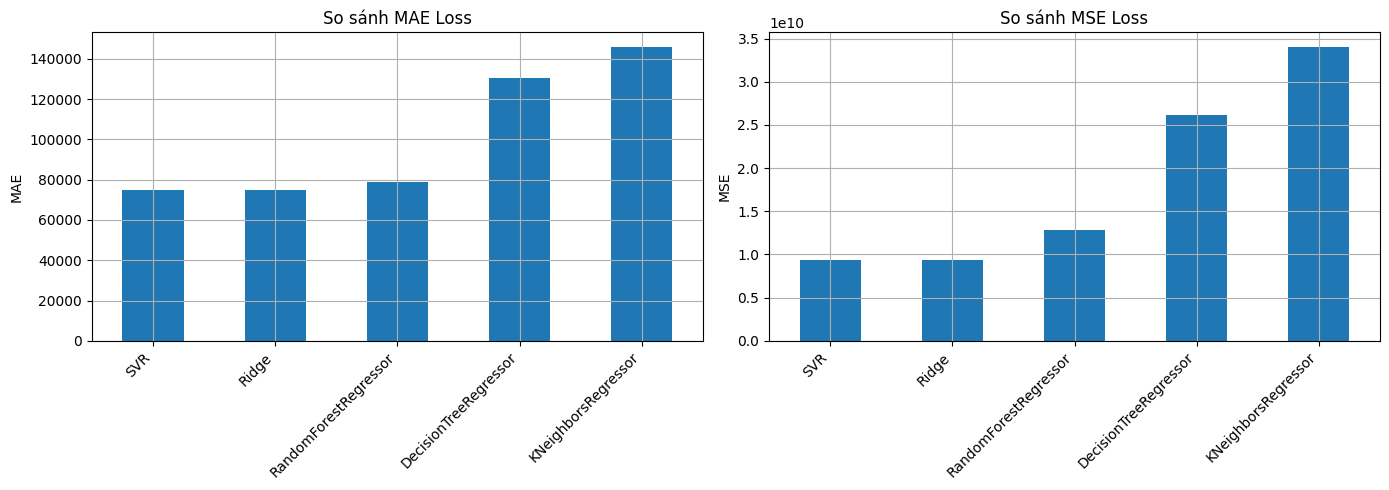

In [99]:
import matplotlib.pyplot as plt
import pandas as pd

# Chuyển sang DataFrame
df_metrics = pd.DataFrame(model_results).T
df_metrics_sorted = df_metrics.sort_values(by='MAE')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ MSE
df_metrics_sorted['MSE'].plot(kind='bar', ax=axes[1], title='So sánh MSE Loss')
axes[1].set_ylabel('MSE')
axes[1].set_xticklabels(df_metrics_sorted.index, rotation=45, ha='right')
axes[1].grid(True)

# Biểu đồ MAE
df_metrics_sorted['MAE'].plot(kind='bar', ax=axes[0], title='So sánh MAE Loss')
axes[0].set_ylabel('MAE')
axes[0].set_xticklabels(df_metrics_sorted.index, rotation=45, ha='right')
axes[0].grid(True)

plt.tight_layout()
plt.show()
